In [649]:
import sys
print(sys.executable)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from nba_api.stats.static import players
from nba_api.stats.static import teams
from nba_api.stats.endpoints import shotchartdetail

c:\Users\pavan\OneDrive\Documents\Python\NBA_Shot_Selection_Scoring_Efficiency_Analysis\.venv\Scripts\python.exe


## Stage 1: Single-Player Test (LeBron)

In [650]:
result = players.find_players_by_full_name("LeBron James")
first_player = result[0]
print(first_player)

player_id = first_player['id']
print(player_id)


{'id': 2544, 'full_name': 'LeBron James', 'first_name': 'LeBron', 'last_name': 'James', 'is_active': True}
2544


In [651]:
shot_chart = shotchartdetail.ShotChartDetail(
    team_id = 0,
    player_id = player_id,
    season_nullable = '2024-25',
    season_type_all_star = 'Regular Season',
    context_measure_simple = 'FGA'
)
shots = shot_chart.get_data_frames()[0]

In [652]:
print(shots.shape)
print(shots.columns)
shots.head()

(1270, 24)
Index(['GRID_TYPE', 'GAME_ID', 'GAME_EVENT_ID', 'PLAYER_ID', 'PLAYER_NAME',
       'TEAM_ID', 'TEAM_NAME', 'PERIOD', 'MINUTES_REMAINING',
       'SECONDS_REMAINING', 'EVENT_TYPE', 'ACTION_TYPE', 'SHOT_TYPE',
       'SHOT_ZONE_BASIC', 'SHOT_ZONE_AREA', 'SHOT_ZONE_RANGE', 'SHOT_DISTANCE',
       'LOC_X', 'LOC_Y', 'SHOT_ATTEMPTED_FLAG', 'SHOT_MADE_FLAG', 'GAME_DATE',
       'HTM', 'VTM'],
      dtype='str')


,GRID_TYPE,GAME_ID,GAME_EVENT_ID,PLAYER_ID,PLAYER_NAME,TEAM_ID,TEAM_NAME,PERIOD,MINUTES_REMAINING,SECONDS_REMAINING,...,SHOT_ZONE_AREA,SHOT_ZONE_RANGE,SHOT_DISTANCE,LOC_X,LOC_Y,SHOT_ATTEMPTED_FLAG,SHOT_MADE_FLAG,GAME_DATE,HTM,VTM
0,Shot Chart Detail,0022400015,14,2544,LeBron James,1610612747,Los Angeles Lakers,1,10,44,...,Center(C),Less Than 8 ft.,5,56,-1,1,0,20241115,SAS,LAL
1,Shot Chart Detail,0022400015,36,2544,LeBron James,1610612747,Los Angeles Lakers,1,8,43,...,Center(C),Less Than 8 ft.,1,-10,4,1,1,20241115,SAS,LAL
2,Shot Chart Detail,0022400015,145,2544,LeBron James,1610612747,Los Angeles Lakers,1,1,18,...,Center(C),Less Than 8 ft.,0,0,0,1,1,20241115,SAS,LAL
3,Shot Chart Detail,0022400015,185,2544,LeBron James,1610612747,Los Angeles Lakers,2,10,53,...,Center(C),Less Than 8 ft.,3,-12,29,1,1,20241115,SAS,LAL
4,Shot Chart Detail,0022400015,211,2544,LeBron James,1610612747,Los Angeles Lakers,2,8,9,...,Center(C),Less Than 8 ft.,1,11,14,1,0,20241115,SAS,LAL


In [653]:
shots.info()

<class 'pandas.DataFrame'>
RangeIndex: 1270 entries, 0 to 1269
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   GRID_TYPE            1270 non-null   str  
 1   GAME_ID              1270 non-null   str  
 2   GAME_EVENT_ID        1270 non-null   int64
 3   PLAYER_ID            1270 non-null   int64
 4   PLAYER_NAME          1270 non-null   str  
 5   TEAM_ID              1270 non-null   int64
 6   TEAM_NAME            1270 non-null   str  
 7   PERIOD               1270 non-null   int64
 8   MINUTES_REMAINING    1270 non-null   int64
 9   SECONDS_REMAINING    1270 non-null   int64
 10  EVENT_TYPE           1270 non-null   str  
 11  ACTION_TYPE          1270 non-null   str  
 12  SHOT_TYPE            1270 non-null   str  
 13  SHOT_ZONE_BASIC      1270 non-null   str  
 14  SHOT_ZONE_AREA       1270 non-null   str  
 15  SHOT_ZONE_RANGE      1270 non-null   str  
 16  SHOT_DISTANCE        1270 non-null 

In [654]:
print(shots['SHOT_ZONE_BASIC'].value_counts())
print()
print(shots['SHOT_TYPE'].value_counts())
print()
print(shots['EVENT_TYPE'].value_counts())
print()
print(shots['SHOT_MADE_FLAG'].value_counts())

SHOT_ZONE_BASIC
Restricted Area          386
Above the Break 3        357
In The Paint (Non-RA)    270
Mid-Range                218
Left Corner 3             23
Right Corner 3            14
Backcourt                  2
Name: count, dtype: int64

SHOT_TYPE
2PT Field Goal    874
3PT Field Goal    396
Name: count, dtype: int64

EVENT_TYPE
Made Shot      651
Missed Shot    619
Name: count, dtype: int64

SHOT_MADE_FLAG
1    651
0    619
Name: count, dtype: int64


In [655]:
print(shots.columns[19:23])
shots[['GAME_DATE', 'SHOT_MADE_FLAG']].dtypes

Index(['SHOT_ATTEMPTED_FLAG', 'SHOT_MADE_FLAG', 'GAME_DATE', 'HTM'], dtype='str')


GAME_DATE           str
SHOT_MADE_FLAG    int64
dtype: object

In [656]:
print(shots['SHOT_MADE_FLAG'].mean())

0.5125984251968504


In [657]:
pd.crosstab(shots['SHOT_ZONE_BASIC'], shots['SHOT_TYPE'])

SHOT_TYPE,2PT Field Goal,3PT Field Goal
SHOT_ZONE_BASIC,,
Above the Break 3,0,357
Backcourt,0,2
In The Paint (Non-RA),270,0
Left Corner 3,0,23
Mid-Range,218,0
Restricted Area,386,0
Right Corner 3,0,14


In [658]:
shots['SHOT_VALUE'] = np.where(shots['SHOT_TYPE'] == '3PT Field Goal', 3, 2)

In [659]:
shots['POINTS'] = np.where(shots['SHOT_MADE_FLAG'] == 1, shots['SHOT_VALUE'], 0)

In [660]:
missed = shots[shots['SHOT_MADE_FLAG'] == 0]
print(missed.shape)
print(missed['POINTS'].sum())
print(shots['POINTS'].value_counts())

(619, 26)
0
POINTS
0    619
2    502
3    149
Name: count, dtype: int64


In [661]:
ppa = shots['POINTS'].sum() / len(shots)
print(ppa)

1.1425196850393702


In [662]:
zone_summary = shots.groupby('SHOT_ZONE_BASIC').agg(
    attempts = ('SHOT_MADE_FLAG', 'count'),
    makes = ('SHOT_MADE_FLAG', 'sum'),
    points = ('POINTS', 'sum'),
    fg_pct = ('SHOT_MADE_FLAG', 'mean'),
    ppa = ('POINTS', 'mean')
)
print(zone_summary)

                       attempts  makes  points    fg_pct       ppa
SHOT_ZONE_BASIC                                                   
Above the Break 3           357    136     408  0.380952  1.142857
Backcourt                     2      0       0  0.000000  0.000000
In The Paint (Non-RA)       270    120     240  0.444444  0.888889
Left Corner 3                23      8      24  0.347826  1.043478
Mid-Range                   218     95     190  0.435780  0.871560
Restricted Area             386    287     574  0.743523  1.487047
Right Corner 3               14      5      15  0.357143  1.071429


## Stage 2: Full-League Data Pull

In [663]:
league_chart = shotchartdetail.ShotChartDetail(
    team_id = 1610612737,
    player_id = 0,
    season_nullable = '2024-25',
    season_type_all_star = 'Regular Season',
    context_measure_simple = 'FGA',
    timeout = 120
)
shots_all_truncated = league_chart.get_data_frames()[0]

all_teams = teams.get_teams()
print(all_teams[0])

team_frames = []
for team in all_teams:
    team_chart = shotchartdetail.ShotChartDetail(
        team_id = team['id'],
        player_id = 0,
        season_nullable = '2024-25',
        season_type_all_star = 'Regular Season',
        context_measure_simple = 'FGA',
        timeout = 120
    )
    temp_df = team_chart.get_data_frames()[0]
    team_frames.append(temp_df)
    print(team['full_name'], len(temp_df))
    time.sleep(0.1)

shots_all = pd.concat(team_frames, ignore_index = True)

print(shots_all.shape)

{'id': 1610612737, 'full_name': 'Atlanta Hawks', 'abbreviation': 'ATL', 'nickname': 'Hawks', 'city': 'Atlanta', 'state': 'Georgia', 'year_founded': 1949}
Atlanta Hawks 7528
Boston Celtics 7382
Cleveland Cavaliers 7444
New Orleans Pelicans 7368
Chicago Bulls 7545
Dallas Mavericks 7194
Denver Nuggets 7360
Golden State Warriors 7412
Houston Rockets 7659
Los Angeles Clippers 7075
Los Angeles Lakers 7007
Miami Heat 7138
Milwaukee Bucks 7082
Minnesota Timberwolves 7182
Brooklyn Nets 7060
New York Knicks 7315
Orlando Magic 7034
Indiana Pacers 7326
Philadelphia 76ers 7168
Phoenix Suns 7075
Portland Trail Blazers 7396
Sacramento Kings 7385
San Antonio Spurs 7362
Oklahoma City Thunder 7600
Toronto Raptors 7462
Utah Jazz 7272
Memphis Grizzlies 7654
Washington Wizards 7371
Detroit Pistons 7363
Charlotte Hornets 7308
(219527, 24)


In [664]:
print(shots_all['GAME_ID'].nunique())

1230


In [665]:
print(shots_all['TEAM_ID'].nunique())

30


In [666]:
print(shots_all['PLAYER_ID'].nunique())

566


In [667]:
print(shots_all['GAME_DATE'].min())

20241022


In [668]:
print(shots_all['GAME_DATE'].max())

20250413


In [669]:
print((shots_all['PLAYER_ID'] == 2544).sum())

1270


In [670]:
shots_all.to_csv('../data/shots_2024_25.csv', index = False)

In [671]:
print(shots_all.duplicated().sum())
print(shots_all.isna().sum())
shots_all['SHOT_ZONE_BASIC'].value_counts()

0
GRID_TYPE              0
GAME_ID                0
GAME_EVENT_ID          0
PLAYER_ID              0
PLAYER_NAME            0
TEAM_ID                0
TEAM_NAME              0
PERIOD                 0
MINUTES_REMAINING      0
SECONDS_REMAINING      0
EVENT_TYPE             0
ACTION_TYPE            0
SHOT_TYPE              0
SHOT_ZONE_BASIC        0
SHOT_ZONE_AREA         0
SHOT_ZONE_RANGE        0
SHOT_DISTANCE          0
LOC_X                  0
LOC_Y                  0
SHOT_ATTEMPTED_FLAG    0
SHOT_MADE_FLAG         0
GAME_DATE              0
HTM                    0
VTM                    0
dtype: int64


SHOT_ZONE_BASIC
Above the Break 3        68358
Restricted Area          61190
In The Paint (Non-RA)    44475
Mid-Range                21402
Left Corner 3            12188
Right Corner 3           11397
Backcourt                  517
Name: count, dtype: int64

In [672]:
def add_points(df):
    df['SHOT_VALUE'] = np.where(df['SHOT_TYPE'] == '3PT Field Goal', 3, 2)
    df['POINTS'] = np.where(df['SHOT_MADE_FLAG'] == 1, df['SHOT_VALUE'], 0)
    return df

In [673]:
add_points(shots_all)
missed = shots_all[shots_all['SHOT_MADE_FLAG'] == 0]
print(missed.shape)
print(missed['POINTS'].sum())
print(shots_all['POINTS'].value_counts())

(116961, 26)
0
POINTS
0    116961
2     69262
3     33304
Name: count, dtype: int64


In [674]:
def add_zone_summary(df):

    zone_summary = df.groupby('SHOT_ZONE_BASIC').agg(
        attempts = ('SHOT_MADE_FLAG', 'count'),
        makes = ('SHOT_MADE_FLAG', 'sum'),
        points = ('POINTS', 'sum'),
        fg_pct = ('SHOT_MADE_FLAG', 'mean'),
        ppa = ('POINTS', 'mean'),
    )
    zone_summary['attempt_share'] = zone_summary['attempts'] / zone_summary['attempts'].sum()
    return zone_summary

In [675]:
zone_summary = add_zone_summary(shots_all)
print(zone_summary)

                       attempts  makes  points    fg_pct       ppa  \
SHOT_ZONE_BASIC                                                      
Above the Break 3         68358  24143   72427  0.353185  1.059525   
Backcourt                   517     12      36  0.023211  0.069632   
In The Paint (Non-RA)     44475  19734   39468  0.443710  0.887420   
Left Corner 3             12188   4706   14118  0.386117  1.158352   
Mid-Range                 21402   8925   17852  0.417017  0.834128   
Restricted Area           61190  40603   81206  0.663556  1.327112   
Right Corner 3            11397   4443   13329  0.389839  1.169518   

                       attempt_share  
SHOT_ZONE_BASIC                       
Above the Break 3           0.311388  
Backcourt                   0.002355  
In The Paint (Non-RA)       0.202595  
Left Corner 3               0.055519  
Mid-Range                   0.097491  
Restricted Area             0.278736  
Right Corner 3              0.051916  


## First Plot

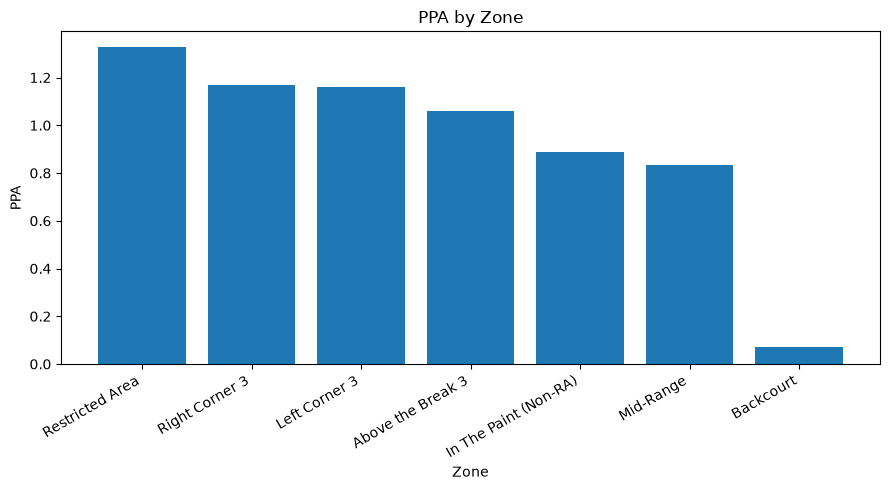

In [677]:
zone_sorted = zone_summary.sort_values('ppa', ascending = False)
# We will keep the backcourt shots for full authenticity of all shot attempts.
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(zone_sorted.index, zone_sorted['ppa'])
ax.set_title('PPA by Zone')
ax.set_xlabel('Zone')
ax.set_ylabel('PPA')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('../visualizations/zone_efficiency.png', dpi=200, bbox_inches='tight')
plt.show()